# Lab 9: Quantum Computing - Rabi Oscillations

**Nombre estudiante:** Ross Anthony Miranda D'Angelo

**C.C:** 1034988497

## Exercise 1: $NH_3$ molecule

An example of the quantum oscillations in two-level systems may be rather unexpected; for example, the ammonium molecule

![NH3](../Sesiones/QC/figures/NH3.png)
![NH3](NH3.png)

 It has two symmetric states that differ by the inversion of the nitrogen atom relative to the plane of the three hydrogen atoms, which are weakly coupled due to quantum-mechanical tunneling of the nitrogen atom through the plane of the hydrogen atoms. Since for this particular molecule, in the absence of external fields, the level splitting $\Delta E$ corresponds to an experimentally convenient frequency $\Omega/2\pi\approx$ 24.79 GHz.

 1. Supose a detuning frequency $\Omega_R/2$.
 2. Compute the Rabi frequency for NH3 molecule in Hz and do a plot of the Rabi oscillation. Supose that the initial state is $\ket{2}$.

 [see](https://phys.libretexts.org/Bookshelves/Quantum_Mechanics/Essential_Graduate_Physics_-_Quantum_Mechanics_(Likharev)/05%3A_Some_Exactly_Solvable_Problems/5.01%3A_Two-level_Systems)

## Exercise: Bell state

1. Creates a quantum circuit for two qubits, consisting of the quantum gates needed to create a `Bell state`  (two entangled qubits). The quantum circuit then terminates with quantum measurements, extracting one bit from each qubit.

2. Add a third qubit by changing to QuantumCircuit(3), and add a second CX gate with qc.cx(1,2). The measurements should then change to 000 and 111, which means all three of these qubits have been entangled.

3. See your results shift by adding qc.x(1) to the end of the circuit.

In [1]:
!pip install -q qiskit qiskit-aer pylatexenc

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.linalg import expm

## Exercise 1: $NH_3$ molecule

Se toma $\Omega/2\pi \approx 24.79$ GHz como la frecuencia de Rabi generalizada y una desintonía (detuning) $\Delta = \Omega_R/2$. De

$$\Omega = \sqrt{\Omega_R^2+\Delta^2} = \sqrt{\Omega_R^2+\dfrac{\Omega_R^2}{4}} = \dfrac{\sqrt{5}}{2}\,\Omega_R$$

se obtiene

$$\boxed{\Omega_R = \dfrac{2}{\sqrt{5}}\,\Omega}\,,\qquad \Delta = \dfrac{\Omega}{\sqrt{5}}$$

In [3]:
f_Omega = 24.79e9                  # Omega/2pi en Hz
Omega   = 2*np.pi*f_Omega          # rad/s

Omega_R = 2*Omega/np.sqrt(5)       # frecuencia de Rabi (rad/s)
Delta   = Omega_R/2                # desintonía (rad/s)

print(f"Omega_R/2pi = {Omega_R/(2*np.pi):.4e} Hz")
print(f"Delta/2pi   = {Delta/(2*np.pi):.4e} Hz")
print(f"Omega/2pi   = {np.sqrt(Omega_R**2+Delta**2)/(2*np.pi):.4e} Hz  (comprobación)")

Omega_R/2pi = 2.2173e+10 Hz
Delta/2pi   = 1.1086e+10 Hz
Omega/2pi   = 2.4790e+10 Hz  (comprobación)


**Estado inicial $\ket{2}$.** Con $c(0)=\begin{pmatrix}0\\1\end{pmatrix}$, las amplitudes son $c(t)=U(t)c(0)=\begin{pmatrix}U_{12}\\U_{22}\end{pmatrix}$. Por simetría con el caso visto en clase:

$$P_2(t) = \cos^2(\Omega t)+\dfrac{\Delta^2}{\Omega^2}\sin^2(\Omega t)\,,\qquad
P_1(t) = \dfrac{\Omega_R^2}{\Omega^2}\sin^2(\Omega t) = \dfrac{4}{5}\sin^2(\Omega t)$$

Es decir, la población nunca pasa por completo a $\ket{1}$: como máximo llega a $4/5$. El periodo de la oscilación es $T=\pi/\Omega \approx 20.2$ ps.

Como comprobación, también se calcula la evolución numéricamente con $U(t)=e^{-iHt/\hbar}$, donde $H/\hbar=\begin{pmatrix}\Delta & \Omega_R\\ \Omega_R & -\Delta\end{pmatrix}$ ($c_x=\hbar\Omega_R$, $c_y=0$, $c_z=\hbar\Delta$).

Periodo T = pi/Omega = 20.17 ps
Máx. diferencia analítico vs numérico: 3.4416913763379853e-15


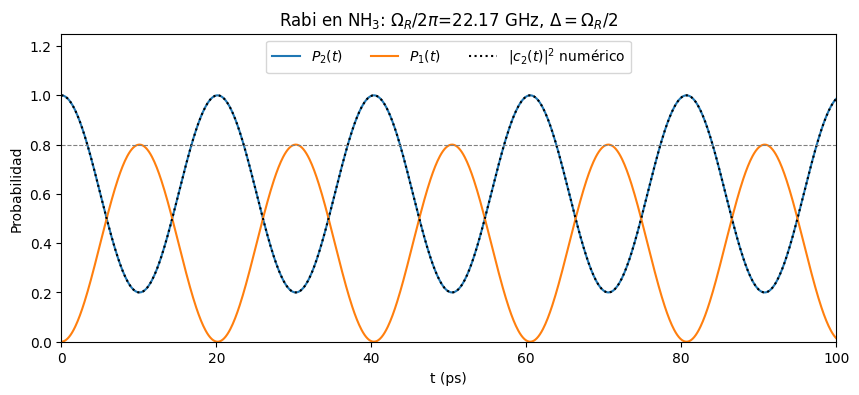

In [4]:
t = np.linspace(0, 100e-12, 1000)   # 0 a 100 ps

# Fórmula analítica
P2 = np.cos(Omega*t)**2 + (Delta/Omega)**2 * np.sin(Omega*t)**2
P1 = (Omega_R/Omega)**2 * np.sin(Omega*t)**2

# Evolución numérica con U(t) = exp(-iHt/hbar)
H_hbar = np.array([[Delta, Omega_R],
                   [Omega_R, -Delta]])
c0 = np.array([0, 1], dtype=complex)          # estado inicial |2>
c_t = np.array([expm(-1j*H_hbar*ti) @ c0 for ti in t])

print("Periodo T = pi/Omega =", f"{np.pi/Omega*1e12:.2f} ps")
print("Máx. diferencia analítico vs numérico:", np.max(np.abs(np.abs(c_t[:,1])**2 - P2)))

plt.figure(figsize=(10, 4))
plt.plot(t*1e12, P2, label=r'$P_2(t)$')
plt.plot(t*1e12, P1, label=r'$P_1(t)$')
plt.plot(t*1e12, np.abs(c_t[:,1])**2, 'k:', label=r'$|c_2(t)|^2$ numérico')
plt.axhline(0.8, color='gray', ls='--', lw=0.8)
plt.xlabel('t (ps)')
plt.ylabel('Probabilidad')
plt.title(rf'Rabi en NH$_3$: $\Omega_R/2\pi$={Omega_R/(2*np.pi)/1e9:.2f} GHz, $\Delta=\Omega_R/2$')
plt.xlim(t.min()*1e12, t.max()*1e12)
plt.ylim(0, 1.25)
plt.legend(loc='upper center', ncol=3)
plt.show()

**Resultado:** la frecuencia de Rabi del NH$_3$ es $\Omega_R/2\pi \approx 22.17$ GHz (con $\Delta/2\pi\approx 11.09$ GHz). Partiendo de $\ket{2}$, el sistema oscila con periodo $\approx 20.2$ ps y la probabilidad máxima de transición a $\ket{1}$ es $\Omega_R^2/\Omega^2 = 0.8$ por culpa de la desintonía.

---

## Exercise: Bell state

In [5]:
from qiskit import QuantumCircuit, transpile
from qiskit_aer import AerSimulator
from qiskit.visualization import plot_histogram

backend = AerSimulator()

def run(qc, shots=1000):
    job = backend.run(transpile(qc, backend), shots=shots)
    return job.result().get_counts(qc)

### 1. Estado de Bell con 2 qubits

$H$ en el qubit 0 y luego $CX(0,1)$:

$$\ket{00}\xrightarrow{H_0}\dfrac{\ket{00}+\ket{01}}{\sqrt2}\xrightarrow{CX}\dfrac{\ket{00}+\ket{11}}{\sqrt2}$$

(notación de Qiskit $\ket{q_1q_0}$). Se esperan solo los resultados `00` y `11`, cada uno con probabilidad $1/2$.

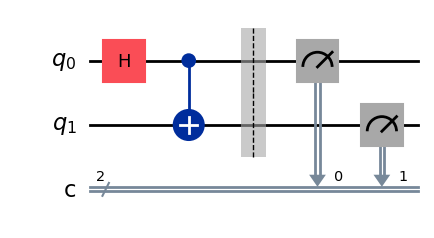

In [6]:
qc = QuantumCircuit(2, 2)
qc.h(0)
qc.cx(0, 1)
qc.barrier()
qc.measure([0, 1], [0, 1])
qc.draw('mpl')

{'11': 522, '00': 478}


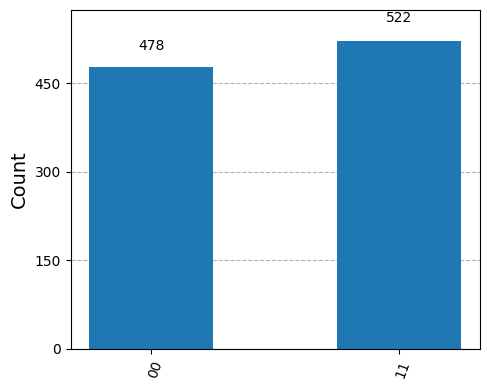

In [7]:
counts = run(qc)
print(counts)
plot_histogram(counts, figsize=(5, 4))

### 2. Tres qubits (estado GHZ)

Con un segundo $CX(1,2)$ el entrelazamiento se extiende al qubit 2:

$$\dfrac{\ket{000}+\ket{111}}{\sqrt2}$$

Solo deben aparecer `000` y `111`.

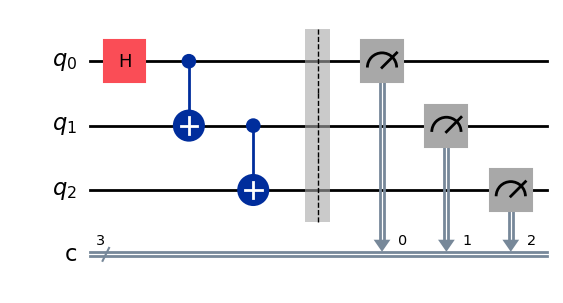

In [8]:
qc3 = QuantumCircuit(3, 3)
qc3.h(0)
qc3.cx(0, 1)
qc3.cx(1, 2)
qc3.barrier()
qc3.measure([0, 1, 2], [0, 1, 2])
qc3.draw('mpl')

{'111': 497, '000': 503}


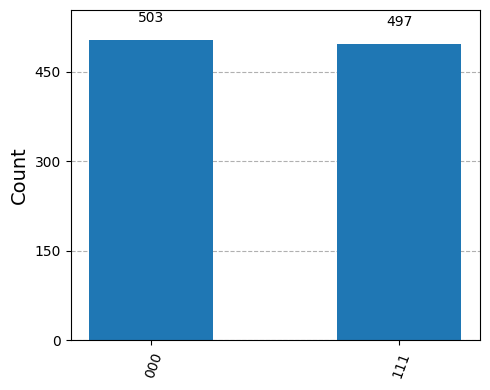

In [9]:
counts3 = run(qc3)
print(counts3)
plot_histogram(counts3, figsize=(5, 4))

### 3. Agregar `qc.x(1)` al final

La compuerta $X$ en el qubit 1 se pone después de las compuertas y antes de medir (si se pone después de la medición no cambia el resultado). Invierte el qubit 1 en ambos términos:

$$X_1\,\dfrac{\ket{000}+\ket{111}}{\sqrt2} = \dfrac{\ket{010}+\ket{101}}{\sqrt2}$$

Los resultados pasan a ser `010` y `101`. Los qubits siguen entrelazados (siempre se mide 0 y 2 iguales y 1 opuesto).

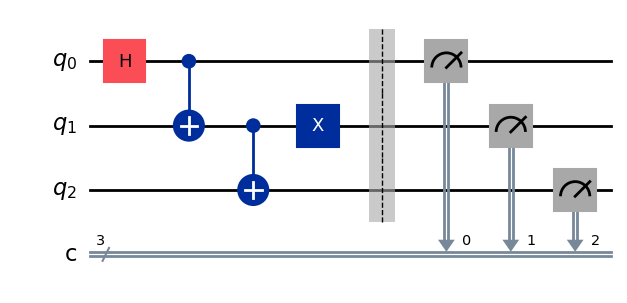

In [10]:
qc3x = QuantumCircuit(3, 3)
qc3x.h(0)
qc3x.cx(0, 1)
qc3x.cx(1, 2)
qc3x.x(1)
qc3x.barrier()
qc3x.measure([0, 1, 2], [0, 1, 2])
qc3x.draw('mpl')

{'101': 499, '010': 501}


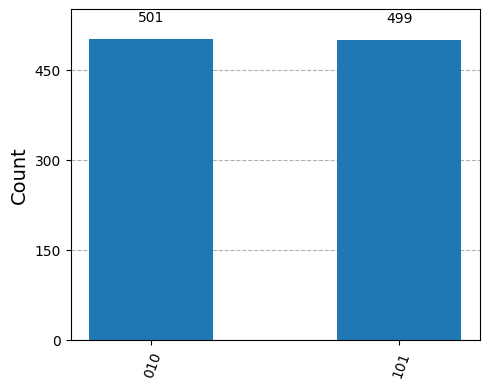

In [11]:
counts3x = run(qc3x)
print(counts3x)
plot_histogram(counts3x, figsize=(5, 4))